# cuDF-Polars filter analysis

This notebook measures only the native filter operation for CPU, CUDA, and Triton. Inputs, masks, backend conversions, and result validation are prepared outside the timed call.

## Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import polars as pl
import torch
import pylibcudf as plc
from rmm.pylibrmm.stream import DEFAULT_STREAM

repo_root = Path.cwd().parents[0] if Path.cwd().name == 'notebooks' else Path.cwd()
python_root = repo_root / 'python' / 'cudf_polars'
if str(python_root) not in sys.path:
    sys.path.insert(0, str(python_root))

from cudf_polars.analysis.operation_benchmark import time_cpu, time_cuda
from cudf_polars.containers import Column, DataFrame, DataType
from cudf_polars.triton.triton_conversion import (
    column_cudf_to_triton,
    dataframe_cudf_to_triton,
)

In [2]:
cudf_stream = DEFAULT_STREAM
num_columns = 4
selectivity = 0.5
warmups = 3
repeats = 10

def benchmark(cases, warmups, repeats, name): 
    benchmark_rows = []
    for num_rows, case in cases.items():
        timings = {
            "cpu": time_cpu(case["cpu"], warmups=warmups, repeats=repeats),
            "cuda": time_cuda(
                case["cuda"],
                stream=cudf_stream,
                warmups=warmups,
                repeats=repeats,
            ),
            "triton": time_cuda(
                case["triton"],
                stream=cudf_stream,
                warmups=warmups,
                repeats=repeats,
            ),
        }
        for backend, timing in timings.items():
            benchmark_rows.append(
                {
                    "operation": name,
                    "backend": backend,
                    "rows": num_rows,
                    "mean_ms": timing.mean_ms,
                    "median_ms": timing.median_ms,
                    "min_ms": timing.min_ms,
                }
            )
        print(f"completed {name} case: {num_rows:,} rows")

    results = pl.DataFrame(benchmark_rows)
    return results

def validate(cases):
    for num_rows, case in cases.items():
        cpu_result = case["cpu"]()
        cuda_result = case["cuda"]()
        triton_result = case["triton"]()
        cudf_stream.synchronize()
        # print(triton_result)
        # triton_result.stream.synchronize()

        expected_rows = case["expected_rows"]
        assert cpu_result.height == expected_rows
        assert cuda_result.num_rows == expected_rows
        assert triton_result.num_rows == expected_rows
        print(f"validated filter output: {num_rows:,} rows -> {expected_rows:,} rows")

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

def plot(results, title):
    plot_df = results.sort("rows")

    for backend in plot_df["backend"].unique():
        data = plot_df.filter(pl.col("backend") == backend)

        plt.plot(
            data["rows"].to_list(),
            data["median_ms"].to_list(),
            marker="o",
            label=backend,
        )

    plt.xscale("log")
    plt.gca().xaxis.set_major_formatter(
        FuncFormatter(lambda value, _: f"{value:,.0f}")
    )
    plt.xlabel("Rows")
    plt.ylabel("Median time (ms)")
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## Filter


In [ ]:


sizes = (200_000, 600_000, 2_000_000, 6_000_000, 12_000_000, 20_000_000)

filter_cases = {}

for num_rows in sizes:
    num_columns = 8
    rng = np.random.default_rng(42)

    values = {
        f'c{i}': rng.standard_normal(num_rows).astype(np.float32)
        for i in range(num_columns)
    }

    mask_values = rng.random(num_rows) < 0.5

    cpu_frame = pl.DataFrame(values)
    cpu_mask = pl.Series('mask', mask_values)

    cudf_stream = DEFAULT_STREAM
    cudf_frame = DataFrame.from_polars(cpu_frame, stream=cudf_stream)

    cudf_mask = Column(
        plc.Column.from_arrow(cpu_mask, stream=cudf_stream),
        dtype=DataType(pl.Boolean()),
        name='mask',
    )

    triton_frame = dataframe_cudf_to_triton(cudf_frame)
    triton_mask = column_cudf_to_triton(
        cudf_mask,
        name='mask',
        stream=cudf_stream,
    )

    cpu_operation = lambda frame=cpu_frame, mask=cpu_mask: frame.filter(mask)
    cuda_operation = lambda frame=cudf_frame, mask=cudf_mask: frame.filter(mask)
    triton_operation = lambda frame=triton_frame, mask=triton_mask: frame.filter(mask)

    expected_rows = mask_values.sum()

    print(
        f'{num_rows:,} rows, '
        f'{num_columns} columns, '
        f'selectivity={mask_values.mean():.3f}'
    )
    print(expected_rows)

    filter_cases[num_rows] = {
        "cpu": cpu_operation,
        "cuda": cuda_operation,
        "triton": triton_operation,
        "expected_rows": expected_rows,
    }

200,000 rows, 8 columns, selectivity=0.501
100247
600,000 rows, 8 columns, selectivity=0.500
300094
2,000,000 rows, 8 columns, selectivity=0.499
998734
6,000,000 rows, 8 columns, selectivity=0.500
3000173
12,000,000 rows, 8 columns, selectivity=0.500
5998103
20,000,000 rows, 8 columns, selectivity=0.500
10001179


In [35]:
filter_results = benchmark(filter_cases, warmups=warmups, repeats=repeats, name="filter")
filter_results

completed filter case: 200,000 rows
completed filter case: 600,000 rows
completed filter case: 2,000,000 rows
completed filter case: 6,000,000 rows
completed filter case: 12,000,000 rows
completed filter case: 20,000,000 rows


operation,backend,rows,mean_ms,median_ms,min_ms
str,str,i64,f64,f64,f64
"""filter""","""cpu""",200000,0.5334487,0.4971925,0.197265
"""filter""","""cuda""",200000,1.095939,1.117696,0.88
"""filter""","""triton""",200000,0.719565,0.70784,0.468992
"""filter""","""cpu""",600000,0.5203206,0.519502,0.364093
"""filter""","""cuda""",600000,2.795062,2.805552,2.54784
…,…,…,…,…,…
"""filter""","""cuda""",12000000,10.415082,10.43248,9.969792
"""filter""","""triton""",12000000,7.832797,7.81168,7.697056
"""filter""","""cpu""",20000000,27.093729,26.979052,26.611409


In [36]:
validate(filter_cases)

validated filter output: 200,000 rows -> 100,247 rows
validated filter output: 600,000 rows -> 300,094 rows
validated filter output: 2,000,000 rows -> 998,734 rows
validated filter output: 6,000,000 rows -> 3,000,173 rows
validated filter output: 12,000,000 rows -> 5,998,103 rows
validated filter output: 20,000,000 rows -> 10,001,179 rows


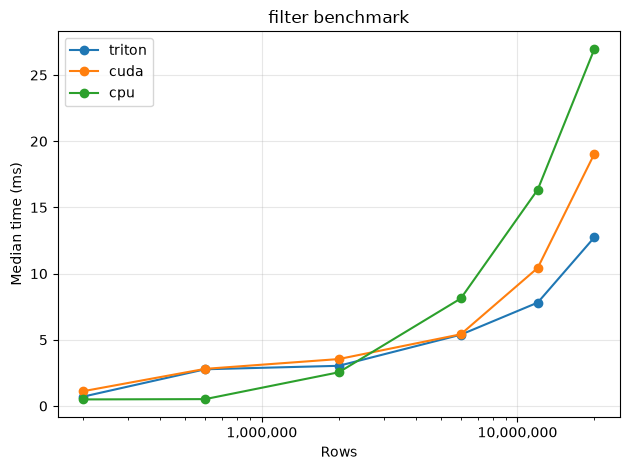

In [37]:
plot(filter_results, "filter benchmark")

## Join benchmark

The join benchmark prepares the key columns before timing. CPU uses Polars `join`, CUDA uses libcudf `inner_join`, and Triton uses the prepared `join_pairs` operation. No conversion, expression evaluation, or result inspection is included in the timed call.

In [42]:
from cudf_polars.analysis.operation_benchmark import generate_join_data
from cudf_polars.triton.triton_operations.join_triton import join_pairs

join_cases = {}
sizes = (100_000, 1_000_000, 10_000_000)

for num_rows in sizes:
    join_data = generate_join_data(num_rows, num_columns=4)
    left_frame = DataFrame.from_polars(join_data.left, stream=cudf_stream)
    right_frame = DataFrame.from_polars(join_data.right, stream=cudf_stream)

    left_key = column_cudf_to_triton(
        left_frame.column_map[join_data.key],
        name=join_data.key,
        stream=cudf_stream,
    )
    right_key = column_cudf_to_triton(
        right_frame.column_map[join_data.key],
        name=join_data.key,
        stream=cudf_stream,
    )
    triton_device = left_key.obj.device

    cpu_operation = lambda left=join_data.left, right=join_data.right, key=join_data.key: left.join(
        right, on=key, how="inner"
    )
    key = join_data.key
    right_size = join_data.right.height
    cuda_operation = lambda left=left_frame, right=right_frame, key=key: plc.join.inner_join(
        plc.Table([left.column_map[key].obj]),
        plc.Table([right.column_map[key].obj]),
        plc.types.NullEquality.EQUAL,
        stream=cudf_stream,
    )
    triton_operation = lambda left=left_key, right=right_key, n_left=num_rows, n_right=right_size: join_pairs(
        [left],
        [right],
        "Inner",
        True,
        device=triton_device,
        n_left=n_left,
        n_right=n_right,
    )

    expected_rows = num_rows
    join_cases[num_rows] = {
        "cpu": cpu_operation,
        "cuda": cuda_operation,
        "triton": triton_operation,
        "expected_rows": expected_rows,
    }
    print(
        f"{num_rows:,} left rows, {join_data.right.height:,} right rows, "
        f"{expected_rows:,} expected matches"
    )

100,000 left rows, 25,000 right rows, 100,000 expected matches
1,000,000 left rows, 250,000 right rows, 1,000,000 expected matches
10,000,000 left rows, 2,500,000 right rows, 10,000,000 expected matches


In [43]:
join_results = benchmark(join_cases, warmups=warmups, repeats=repeats, name="join")
join_results

completed join case: 100,000 rows
completed join case: 1,000,000 rows
completed join case: 10,000,000 rows


operation,backend,rows,mean_ms,median_ms,min_ms
str,str,i64,f64,f64,f64
"""join""","""cpu""",100000,2.4811762,2.5765015,1.842505
"""join""","""cuda""",100000,0.439165,0.425792,0.412672
"""join""","""triton""",100000,3.708778,3.728816,3.449856
"""join""","""cpu""",1000000,8.962939,8.835376,8.496364
"""join""","""cuda""",1000000,2.540509,2.5128,2.343936
"""join""","""triton""",1000000,14.72889,14.695936,12.473344
"""join""","""cpu""",10000000,125.467589,125.818687,117.532185
"""join""","""cuda""",10000000,17.209043,16.562,16.402143
"""join""","""triton""",10000000,412.548437,401.708328,351.431671


In [44]:
for num_rows, case in join_cases.items():
    cpu_result = case["cpu"]()
    cuda_left, cuda_right = case["cuda"]()
    triton_left, triton_right = case["triton"]()
    cudf_stream.synchronize()

    expected_rows = case["expected_rows"]
    assert cpu_result.height == expected_rows
    assert cuda_left.size() == expected_rows
    assert cuda_right.size() == expected_rows
    assert triton_left.numel() == expected_rows
    assert triton_right.numel() == expected_rows
    print(f"validated join output: {num_rows:,} left rows -> {expected_rows:,} matches")

validated join output: 100,000 left rows -> 100,000 matches
validated join output: 1,000,000 left rows -> 1,000,000 matches
validated join output: 10,000,000 left rows -> 10,000,000 matches


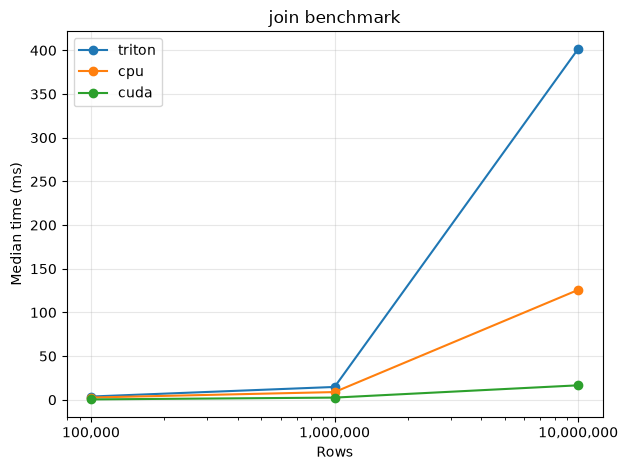

In [45]:
plot(join_results, "join benchmark")

## Distinct benchmark

Distinct benchmarks the native operation on one repeated integer key. Input preparation and result validation are outside the timed call.

In [ ]:
from cudf_polars.triton.triton_operations.distinct_triton import distinct_triton_indices
sizes = (100_000, 1_000_000, 10_000_000)
distinct_cases = {}
distinct_keep = plc.stream_compaction.DuplicateKeepOption.KEEP_FIRST
for num_rows in sizes:
    num_unique = max(1, num_rows // 10)
    values = np.arange(num_rows, dtype=np.int64) % num_unique
    cpu_frame = pl.DataFrame({"key": values})
    cudf_frame = DataFrame.from_polars(cpu_frame, stream=cudf_stream)
    triton_key = column_cudf_to_triton(
        cudf_frame.column_map["key"], name="key", stream=cudf_stream
    )
    cudf_table = plc.Table([cudf_frame.column_map["key"].obj])
    cpu_operation = lambda frame=cpu_frame: frame.unique(maintain_order=False)
    cuda_operation = lambda table=cudf_table: plc.stream_compaction.stable_distinct(
        table,
        [0],
        distinct_keep,
        plc.types.NullEquality.EQUAL,
        plc.types.NanEquality.ALL_EQUAL,
        stream=cudf_stream,
    )
    triton_operation = lambda key=triton_key: distinct_triton_indices(
        [key],
        torch.argsort(key.obj, stable=True),
        distinct_keep,
    )

    distinct_cases[num_rows] = {
        "cpu": cpu_operation,
        "cuda": cuda_operation,
        "triton": triton_operation,
        "expected_rows": num_unique,
    }
    print(f"{num_rows:,} rows, {num_unique:,} expected distinct values")

10,000 rows, 1,000 expected distinct values
100,000 rows, 10,000 expected distinct values
1,000,000 rows, 100,000 expected distinct values


In [13]:
distinct_results = benchmark(
    distinct_cases, warmups=warmups, repeats=repeats, name="distinct"
)
distinct_results

completed distinct case: 10,000 rows
completed distinct case: 100,000 rows
completed distinct case: 1,000,000 rows


operation,backend,rows,mean_ms,median_ms,min_ms
str,str,i64,f64,f64,f64
"""distinct""","""cpu""",10000,0.5518958,0.535599,0.219356
"""distinct""","""cuda""",10000,0.321251,0.318544,0.271232
"""distinct""","""triton""",10000,0.76729,0.676896,0.617472
"""distinct""","""cpu""",100000,1.0986202,1.080903,1.033427
"""distinct""","""cuda""",100000,0.842512,0.749984,0.713728
"""distinct""","""triton""",100000,0.805712,0.794944,0.676544
"""distinct""","""cpu""",1000000,4.9930802,4.8271355,4.52035
"""distinct""","""cuda""",1000000,3.111354,3.074992,2.843392
"""distinct""","""triton""",1000000,1.795862,1.732224,1.687712


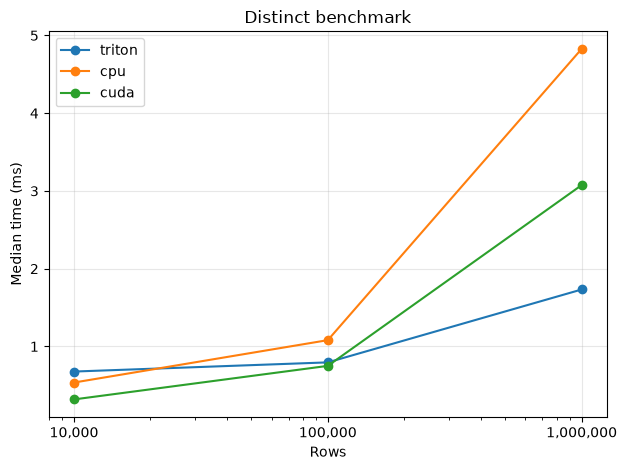

In [14]:
for num_rows, case in distinct_cases.items():
    assert case["cpu"]().height == case["expected_rows"]
    assert case["cuda"]().num_rows() == case["expected_rows"]
    assert case["triton"]().numel() == case["expected_rows"]

plot(distinct_results, "Distinct benchmark")

## Sort benchmark

Sort benchmarks a stable ascending sort of one integer key. The timed calls operate on prepared native inputs.

In [15]:
from cudf_polars.triton.triton_operations.sort_triton import sort_indices

sort_cases = {}
sort_order = [plc.types.Order.ASCENDING]
sort_null_order = [plc.types.NullOrder.BEFORE]

for num_rows in sizes:
    rng = np.random.default_rng(42)
    values = rng.permutation(num_rows).astype(np.int64)
    cpu_frame = pl.DataFrame({"key": values})
    cudf_frame = DataFrame.from_polars(cpu_frame, stream=cudf_stream)
    triton_key = column_cudf_to_triton(
        cudf_frame.column_map["key"], name="key", stream=cudf_stream
    )
    cudf_table = plc.Table([cudf_frame.column_map["key"].obj])

    cpu_operation = lambda frame=cpu_frame: frame.sort("key")
    cuda_operation = lambda table=cudf_table: plc.sorting.stable_sort_by_key(
        table, table, sort_order, sort_null_order, stream=cudf_stream
    )
    triton_operation = lambda key=triton_key: sort_indices(
        [key], sort_order, sort_null_order, torch.cuda.current_stream()
    )
    sort_cases[num_rows] = {
        "cpu": cpu_operation, "cuda": cuda_operation,
        "triton": triton_operation, "expected_rows": num_rows,
    }
    print(f"{num_rows:,} rows")

10,000 rows
100,000 rows
1,000,000 rows


In [16]:
sort_results = benchmark(
    sort_cases, warmups=warmups, repeats=repeats, name="sort"
)
sort_results

completed sort case: 10,000 rows
completed sort case: 100,000 rows
completed sort case: 1,000,000 rows


operation,backend,rows,mean_ms,median_ms,min_ms
str,str,i64,f64,f64,f64
"""sort""","""cpu""",10000,0.3874897,0.3879455,0.323658
"""sort""","""cuda""",10000,0.301469,0.260768,0.238976
"""sort""","""triton""",10000,0.419434,0.416576,0.367616
"""sort""","""cpu""",100000,0.8115714,0.8356335,0.567031
"""sort""","""cuda""",100000,1.425866,1.40032,0.962976
"""sort""","""triton""",100000,0.512099,0.497152,0.432128
"""sort""","""cpu""",1000000,4.1473403,4.151056,3.725839
"""sort""","""cuda""",1000000,3.437197,3.448384,3.290208
"""sort""","""triton""",1000000,1.472208,1.440688,1.424096


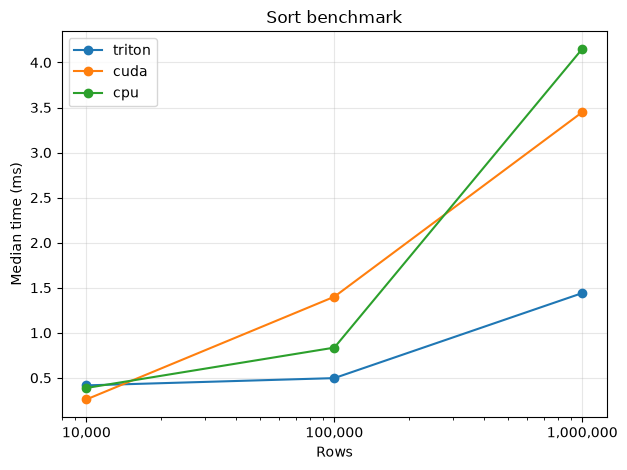

In [17]:
for num_rows, case in sort_cases.items():
    cpu_result = case["cpu"]()
    cuda_result = case["cuda"]()
    triton_result = case["triton"]()
    cudf_stream.synchronize()
    assert cpu_result.height == case["expected_rows"]
    assert cuda_result.num_rows() == case["expected_rows"]
    assert triton_result.numel() == case["expected_rows"]

plot(sort_results, "Sort benchmark")

## Groupby benchmark

Groupby benchmarks a `key -> sum(value)` aggregation using the prepared native inputs.


In [18]:
from cudf_polars.triton.components.base_triton import ExecutionContext, TritonCol, TritonNamedExpr
from cudf_polars.triton.triton_conversion import dataframe_cudf_to_triton
from cudf_polars.triton.components.agg_triton import TritonAgg
from cudf_polars.triton.ir_triton import groupby_triton

groupby_cases = {}
groupby_key_dtype = torch.int64
groupby_value_dtype = torch.float32

groupby_agg = plc.aggregation.sum()

for num_rows in sizes:
    num_groups = max(1, num_rows // 100)
    rng = np.random.default_rng(42)
    values = {
        "key": np.arange(num_rows, dtype=np.int64) % num_groups,
        "value": rng.standard_normal(num_rows).astype(np.float32),
    }
    cpu_frame = pl.DataFrame(values)
    cudf_frame = DataFrame.from_polars(cpu_frame, stream=cudf_stream)
    triton_frame = dataframe_cudf_to_triton(cudf_frame)

    cudf_grouper = plc.groupby.GroupBy(
        plc.Table([cudf_frame.column_map["key"].obj]),
        null_handling=plc.types.NullPolicy.INCLUDE,
        keys_are_sorted=plc.types.Sorted.NO,
        column_order=[plc.types.Order.ASCENDING],
        null_precedence=[plc.types.NullOrder.BEFORE],
    )
    cudf_request = plc.groupby.GroupByRequest(
        cudf_frame.column_map["value"].obj, [groupby_agg]
    )

    triton_keys = (TritonNamedExpr("key", TritonCol(groupby_key_dtype, "key")),)
    triton_aggs = (
        TritonNamedExpr(
            "value_sum",
            TritonAgg(
                groupby_value_dtype,
                "sum",
                None,
                ExecutionContext.GROUPBY,
                TritonCol(groupby_value_dtype, "value"),
            ),
        ),
    )

    cpu_operation = lambda frame=cpu_frame: frame.group_by("key").agg(
        pl.col("value").sum().alias("value_sum")
    )
    cuda_operation = lambda grouper=cudf_grouper, request=cudf_request: grouper.aggregate(
        [request], stream=cudf_stream
    )
    triton_operation = lambda frame=triton_frame: groupby_triton(
        frame, triton_keys, triton_aggs, False, None
    )

    groupby_cases[num_rows] = {
        "cpu": cpu_operation,
        "cuda": cuda_operation,
        "triton": triton_operation,
        "expected_rows": num_groups,
    }
    print(f"{num_rows:,} rows, {num_groups:,} expected groups")

10,000 rows, 100 expected groups
100,000 rows, 1,000 expected groups
1,000,000 rows, 10,000 expected groups


In [19]:
groupby_results = benchmark(
    groupby_cases, warmups=warmups, repeats=repeats, name="groupby"
)
groupby_results

completed groupby case: 10,000 rows
completed groupby case: 100,000 rows
completed groupby case: 1,000,000 rows


operation,backend,rows,mean_ms,median_ms,min_ms
str,str,i64,f64,f64,f64
"""groupby""","""cpu""",10000,1.038655,1.085376,0.421229
"""groupby""","""cuda""",10000,1.008947,0.817152,0.733184
"""groupby""","""triton""",10000,1.884262,1.446912,1.143808
"""groupby""","""cpu""",100000,1.16526,1.2460235,0.532992
"""groupby""","""cuda""",100000,2.830746,2.740224,1.789952
"""groupby""","""triton""",100000,2.271642,2.137088,1.978368
"""groupby""","""cpu""",1000000,4.0769325,3.9745255,3.611281
"""groupby""","""cuda""",1000000,5.95456,5.545472,5.328896
"""groupby""","""triton""",1000000,6.542336,6.284288,5.779456


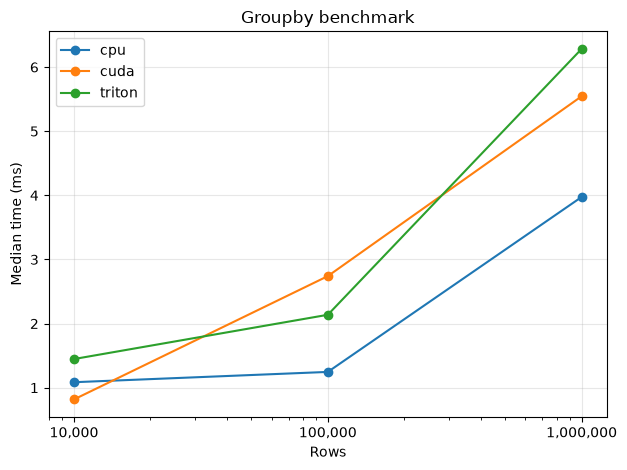

In [20]:
for num_rows, case in groupby_cases.items():
    cpu_result = case["cpu"]()
    cuda_keys, cuda_values = case["cuda"]()
    triton_result = case["triton"]()
    cudf_stream.synchronize()
    assert cpu_result.height == case["expected_rows"]
    assert cuda_keys.num_rows() == case["expected_rows"]
    assert cuda_values[0].num_rows() == case["expected_rows"]
    assert triton_result.num_rows == case["expected_rows"]

plot(groupby_results, "Groupby benchmark")

## Filter and sort benchmark

This benchmark measures two layers: filtering the input and sorting the retained rows by one key. Both operators run inside the timed callable for each backend.

In [13]:
from cudf_polars.triton.triton_operations.sort_triton import sort_indices

filter_sort_cases = {}
sort_sizes = (10_000, 100_000, 1_000_000)
sort_order = [plc.types.Order.ASCENDING]
sort_null_order = [plc.types.NullOrder.BEFORE]

for num_rows in sort_sizes:
    rng = np.random.default_rng(42)
    values = rng.permutation(num_rows).astype(np.int64)
    mask_values = (np.arange(num_rows) % 2) == 0
    cpu_frame = pl.DataFrame({"key": values, "value": values.astype(np.float32)})
    cpu_mask = pl.Series("mask", mask_values)

    cudf_frame = DataFrame.from_polars(cpu_frame, stream=cudf_stream)
    cudf_mask = Column(
        plc.Column.from_arrow(cpu_mask, stream=cudf_stream),
        dtype=DataType(pl.Boolean()),
        name="mask",
    )
    triton_frame = dataframe_cudf_to_triton(cudf_frame)
    triton_mask = column_cudf_to_triton(cudf_mask, name="mask", stream=cudf_stream)

    def cpu_filter_sort(frame=cpu_frame, mask=cpu_mask):
        return frame.filter(mask).sort("key")

    def cuda_filter_sort(frame=cudf_frame, mask=cudf_mask):
        filtered = frame.filter(mask)
        return plc.sorting.stable_sort_by_key(
            filtered.table,
            plc.Table([filtered.column_map["key"].obj]),
            sort_order,
            sort_null_order,
            stream=cudf_stream,
        )

    def triton_filter_sort(frame=triton_frame, mask=triton_mask):
        filtered = frame.filter(mask)
        return sort_indices(
            [filtered.column_map["key"]],
            sort_order,
            sort_null_order,
            torch.cuda.current_stream(),
        )

    expected_rows = int(mask_values.sum())
    filter_sort_cases[num_rows] = {
        "cpu": cpu_filter_sort,
        "cuda": cuda_filter_sort,
        "triton": triton_filter_sort,
        "expected_rows": expected_rows,
    }

filter_sort_results = benchmark(
    filter_sort_cases, warmups=warmups, repeats=repeats, name="filter + sort"
)
filter_sort_results

completed filter + sort case: 10,000 rows
completed filter + sort case: 100,000 rows
completed filter + sort case: 1,000,000 rows


operation,backend,rows,mean_ms,median_ms,min_ms
str,str,i64,f64,f64,f64
"""filter + sort""","""cpu""",10000,1.16515,1.212649,0.906389
"""filter + sort""","""cuda""",10000,1.426432,0.955392,0.90112
"""filter + sort""","""triton""",10000,1.808691,1.366528,1.32096
"""filter + sort""","""cpu""",100000,1.738579,1.456961,1.029503
"""filter + sort""","""cuda""",100000,4.788122,3.929088,2.873344
"""filter + sort""","""triton""",100000,1.864602,1.402368,1.364992
"""filter + sort""","""cpu""",1000000,5.7339547,5.7218755,4.914517
"""filter + sort""","""cuda""",1000000,18.062035,15.51376,4.270848
"""filter + sort""","""triton""",1000000,1.210912,1.13152,1.091584


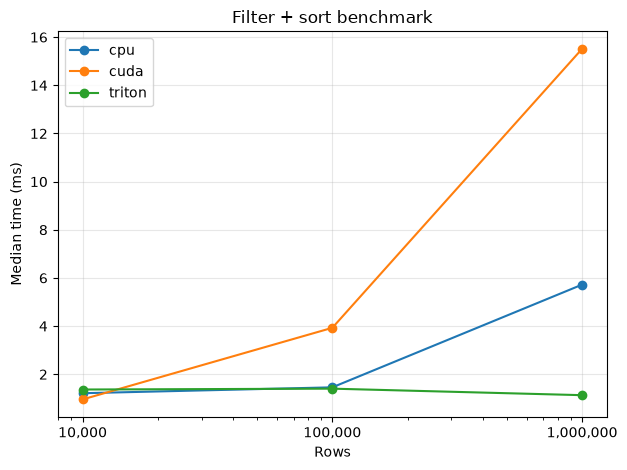

In [14]:
for num_rows, case in filter_sort_cases.items():
    cpu_result = case["cpu"]()
    cuda_result = case["cuda"]()
    triton_result = case["triton"]()
    cudf_stream.synchronize()
    assert cpu_result.height == case["expected_rows"]
    assert cuda_result.num_rows() == case["expected_rows"]
    assert triton_result.numel() == case["expected_rows"]

plot(filter_sort_results, "Filter + sort benchmark")

## Filter and distinct benchmark

This benchmark measures two layers: filtering the input and removing duplicate keys from the retained rows. The complete pipeline is timed for each backend.

In [9]:
from cudf_polars.triton.triton_operations.distinct_triton import distinct_triton_indices


filter_distinct_cases = {}
distinct_sizes = (10_000, 100_000, 1_000_000)
distinct_keep = plc.stream_compaction.DuplicateKeepOption.KEEP_FIRST

for num_rows in distinct_sizes:
    num_unique = max(1, num_rows // 10)
    values = np.arange(num_rows, dtype=np.int64) % num_unique
    mask_values = (np.arange(num_rows) % 3) != 0
    cpu_frame = pl.DataFrame({"key": values})
    cpu_mask = pl.Series("mask", mask_values)

    cudf_frame = DataFrame.from_polars(cpu_frame, stream=cudf_stream)
    cudf_mask = Column(
        plc.Column.from_arrow(cpu_mask, stream=cudf_stream),
        dtype=DataType(pl.Boolean()),
        name="mask",
    )
    triton_frame = dataframe_cudf_to_triton(cudf_frame)
    triton_mask = column_cudf_to_triton(cudf_mask, name="mask", stream=cudf_stream)

    def cpu_filter_distinct(frame=cpu_frame, mask=cpu_mask):
        return frame.filter(mask).unique(maintain_order=False)

    def cuda_filter_distinct(frame=cudf_frame, mask=cudf_mask):
        filtered = frame.filter(mask)
        return plc.stream_compaction.stable_distinct(
            plc.Table([filtered.column_map["key"].obj]),
            [0],
            distinct_keep,
            plc.types.NullEquality.EQUAL,
            plc.types.NanEquality.ALL_EQUAL,
            stream=cudf_stream,
        )

    def triton_filter_distinct(frame=triton_frame, mask=triton_mask):
        filtered = frame.filter(mask)
        key = filtered.column_map["key"]
        return distinct_triton_indices(
            [key], torch.argsort(key.obj, stable=True), distinct_keep
        )

    expected_rows = int(np.unique(values[mask_values]).size)
    filter_distinct_cases[num_rows] = {
        "cpu": cpu_filter_distinct,
        "cuda": cuda_filter_distinct,
        "triton": triton_filter_distinct,
        "expected_rows": expected_rows,
    }

filter_distinct_results = benchmark(
    filter_distinct_cases,
    warmups=warmups,
    repeats=repeats,
    name="filter + distinct",
)
filter_distinct_results

completed filter + distinct case: 10,000 rows
completed filter + distinct case: 100,000 rows
completed filter + distinct case: 1,000,000 rows


operation,backend,rows,mean_ms,median_ms,min_ms
str,str,i64,f64,f64,f64
"""filter + distinct""","""cpu""",10000,1.0528276,1.054003,0.927448
"""filter + distinct""","""cuda""",10000,1.06752,0.80128,0.75264
"""filter + distinct""","""triton""",10000,2.544026,1.959936,1.901568
"""filter + distinct""","""cpu""",100000,1.2523558,1.267442,1.174054
"""filter + distinct""","""cuda""",100000,3.329536,2.65216,1.71008
"""filter + distinct""","""triton""",100000,2.90519,2.305024,2.220032
"""filter + distinct""","""cpu""",1000000,4.3906253,4.37084,3.913128
"""filter + distinct""","""cuda""",1000000,11.624755,10.902528,9.382912
"""filter + distinct""","""triton""",1000000,2.885331,1.614384,1.510624


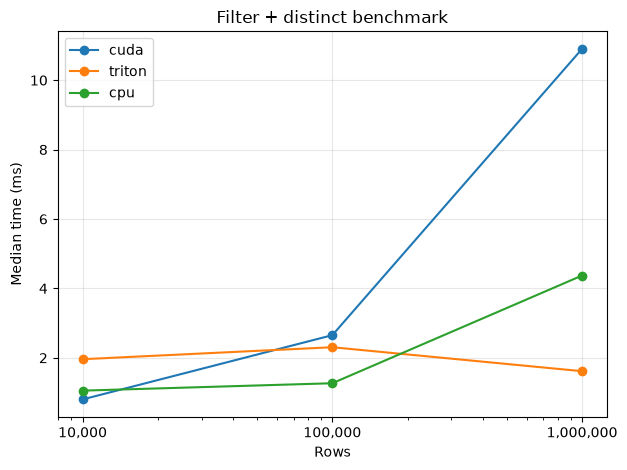

In [10]:
for num_rows, case in filter_distinct_cases.items():
    cpu_result = case["cpu"]()
    cuda_result = case["cuda"]()
    triton_result = case["triton"]()
    cudf_stream.synchronize()
    assert cpu_result.height == case["expected_rows"]
    assert cuda_result.num_rows() == case["expected_rows"]
    assert triton_result.numel() == case["expected_rows"]

plot(filter_distinct_results, "Filter + distinct benchmark")